# Task 5: Machine Learning Classification Model

## 1. Project Overview

### Background
Netflix's catalog contains movies and television shows described by metadata such as release year, genre, country, and content rating. Machine learning can use these features to identify patterns and predict content categories.

### Problem Statement
This project aims to develop and evaluate supervised machine learning models that classify Netflix titles as either **Movies or TV Shows** using selected metadata features.

### Objectives
- Select and prepare relevant features and the target variable.
- Split the dataset into training and testing sets.
- Train Logistic Regression, Decision Tree, and Random Forest classifiers.
- Evaluate model performance using appropriate classification metrics.
- Compare model results and identify the strongest-performing approach on unseen data.

### Methodology
The project will use the cleaned Netflix dataset. Logistic Regression will establish a baseline, while Decision Tree and Random Forest models will capture potentially more complex relationships in the data. A consistent train-test split and preprocessing pipeline will be used to support a fair comparison.

Models will be evaluated using accuracy, precision, recall, F1-score, and confusion matrices. Feature importance may also be examined to understand which metadata variables contribute to Random Forest predictions.

### Business Value
This project demonstrates how supervised machine learning can extract patterns from content metadata and support automated content classification and catalog analysis. It also provides practical experience in model evaluation and evidence-based model selection.

### Scope and Limitations
The analysis is limited to the available dataset and selected metadata features. Performance may be affected by missing values, class imbalance, and limited predictive information. Features that directly reveal the target, such as duration-related fields, will be excluded to reduce target leakage. Identifiers and title-specific fields will also be excluded from the initial models.

Results will be assessed on a held-out test set. Since the dataset represents a particular catalog snapshot, model performance may not generalize to other content catalogs or future data. Gaussian Mixture Models may be explored separately for unsupervised clustering, but they will not be included in the primary supervised classification comparison.

In [1]:
# Imporing required libraries

# Data loading and manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-test splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

# Data preprocessing and feature engineering
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)
from sklearn.impute import SimpleImputer

# Supervised classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Feature importance and model interpretation
from sklearn.inspection import permutation_importance

# Optional: unsupervised clustering exploration
from sklearn.cluster import KMeans

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)


In [2]:
# Load the cleaned Netflix dataset.
df = pd.read_csv("netflix_cleaned.csv")

In [3]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,date_added_year,date_added_month,date_added_day,duration_value,duration_unit,genre_count
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,25,90,min,1
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure",2021,9,24,1,Season,3
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,24,1,Season,3
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,22,91,min,2
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,24,125,min,3


In [4]:

# Examining the target variable: Movie versus TV Show.
print("Target class counts:")
display(df["type"].value_counts(dropna=False))

print("\nTarget class percentages:")
display(
    (df["type"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Target class counts:


type
Movie      6126
TV Show    2664
Name: count, dtype: int64


Target class percentages:


type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64

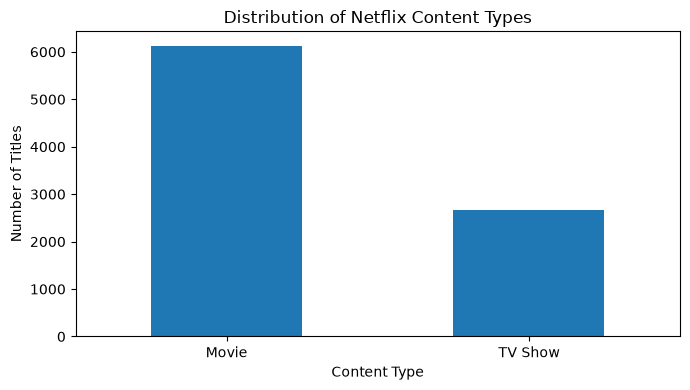

In [5]:

# Visualize the number of titles in each target class.
ax = df["type"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

ax.set_title("Distribution of Netflix Content Types")
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Titles")

plt.tight_layout()
plt.show()


## Step 2: Feature Selection and Target Definition

In this step, I select the features I will use to train my classification models and define the target variable. My goal is to predict whether a Netflix title is a Movie or a TV Show using selected metadata from the dataset.

I will use `release_year`, `genre_count`, `country`, `rating`, and `listed_in` as my initial features. These variables provide information about when a title was released, its genre classification, country of origin, content rating, and genre categories.

I will exclude identifiers such as `show_id` and avoid duration-related features in my initial model because they can make the distinction between Movies and TV Shows too easy, potentially limiting the model's usefulness when applied to new or incomplete records.

Before proceeding, I will verify that the selected columns exist, inspect their data types, and check for missing values. These checks will help me determine the preprocessing steps required before training and evaluating my classification models.

In [6]:
# Define the target variable: Movie or TV Show.
target = "type"
y = df[target].copy()

# Select candidate features for classification.
feature_columns = [
    "release_year",
    "genre_count",
    "country",
    "rating",
    "listed_in"
]

X = df[feature_columns].copy()

# Review the selected inputs and prediction target.
print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)


Feature dataset shape: (8790, 5)
Target dataset shape: (8790,)


In [7]:

# Inspect data types and missing values in the selected features.
print("Feature data types:")
display(X.dtypes)

print("\nMissing values in selected features:")
display(X.isna().sum())

# Check whether the target contains missing values.
print("\nMissing target values:", y.isna().sum())


Feature data types:


release_year    int64
genre_count     int64
country           str
rating            str
listed_in         str
dtype: object


Missing values in selected features:


release_year      0
genre_count       0
country         287
rating            0
listed_in         0
dtype: int64


Missing target values: 0


## Step 3: Data Quality Assessment and Preprocessing Plan

After inspecting my selected features, I found that `release_year`, `genre_count`, `rating`, and `listed_in` have no missing values. However, the `country` column contains 287 missing values. My target variable, `type`, is complete, so no records need to be excluded because of a missing target.

Since my dataset contains both numerical and categorical features, I will use separate preprocessing steps for each data type. I will impute missing country values with an explicit `Unknown` category and apply one-hot encoding to categorical features so that the classification algorithms can process them. I will also build the preprocessing steps into a scikit-learn pipeline to keep the training and evaluation process consistent and prevent information leakage from the test set.

In [8]:

from sklearn.model_selection import train_test_split

# Reserve 20% of the records for final model evaluation.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Confirm the dataset sizes.
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))


Training features: (7032, 5)
Testing features: (1758, 5)

Training target distribution:


type
Movie      69.7
TV Show    30.3
Name: proportion, dtype: float64


Testing target distribution:


type
Movie      69.68
TV Show    30.32
Name: proportion, dtype: float64

### **Build the preprocessing pipeline**
We will now prepare the numerical and categorical features separately. The imputer will be fitted on the training data only, then the fitted transformations will be applied to the test data.

In [9]:
# Separate features by data type.
numeric_features = ["release_year", "genre_count"]
categorical_features = ["country", "rating", "listed_in"]

# Impute missing numeric values and scale numeric features.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Represent missing categories explicitly and encode categorical features.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature group.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline configured successfully.")


Preprocessing pipeline configured successfully.


## Step 4: Train the Baseline Classification Model

I will begin with Logistic Regression as my baseline model for classifying Netflix titles as Movies or TV Shows. Logistic Regression provides a useful starting point for evaluating how well the selected metadata can distinguish between the two content types.

I will combine the preprocessing pipeline with the classifier so that numerical and categorical features are transformed consistently before model training. I will fit the model using the training dataset and reserve the test dataset for evaluating its performance on unseen records.

In [10]:

# Combine preprocessing and classification into one workflow.
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Fit the model using the training data.
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


## Evaluate the Baseline Model

After training the Logistic Regression model, I will evaluate its predictions on the test dataset. I will examine accuracy, precision, recall, and F1-score to understand its overall performance and how effectively it classifies each content type.

I will also inspect the confusion matrix to identify correctly classified titles and cases where Movies are mistaken for TV Shows, or vice versa. These results will provide a baseline for comparison with the Decision Tree and Random Forest models.

In [11]:
# Predict content types for the unseen test records.
y_pred_logistic = logistic_model.predict(X_test)

# Calculate overall accuracy.
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_logistic), 4))

# Review precision, recall, and F1-score for each class.
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))


Logistic Regression Accuracy: 0.992

Classification Report:
              precision    recall  f1-score   support

       Movie       0.99      1.00      0.99      1225
     TV Show       0.99      0.98      0.99       533

    accuracy                           0.99      1758
   macro avg       0.99      0.99      0.99      1758
weighted avg       0.99      0.99      0.99      1758



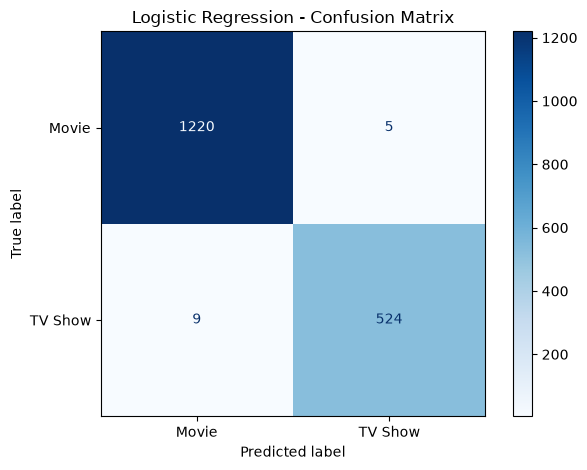

In [12]:
# Visualize the model's classification errors.
cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=logistic_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


**Important check before training the next model**\
Our target is type, and our features include listed_in, rating, country, release_year, and genre_count. Some metadata—particularly listed_in—may contain strong signals about the title's type. This could legitimately explain high performance, but we should investigate whether the model is learning useful patterns or relying on features that effectively reveal the answer.

## step 5: Examine Classification Errors

My Logistic Regression model achieved 99.2% accuracy on the test dataset. I will now examine its confusion matrix to understand the types of classification errors it makes. This will help me assess whether the model performs consistently for Movies and TV Shows before comparing it with more complex classifiers.

In [13]:
# Display the number of correct predictions and misclassifications.
print("Confusion matrix:")
display(pd.DataFrame(
    confusion_matrix(
        y_test,
        y_pred_logistic,
        labels=logistic_model.classes_
    ),
    index=[f"Actual {c}" for c in logistic_model.classes_],
    columns=[f"Predicted {c}" for c in logistic_model.classes_]
))

# Count all incorrect predictions.
errors = (y_test != y_pred_logistic).sum()
print(f"\nIncorrect predictions: {errors} out of {len(y_test)}")


Confusion matrix:


,Predicted Movie,Predicted TV Show
Actual Movie,1220,5
Actual TV Show,9,524



Incorrect predictions: 14 out of 1758


In [14]:


# Create a benchmark that always predicts the most common training class.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)
dummy_accuracy = accuracy_score(y_test, dummy_predictions)

print(f"Dummy baseline accuracy: {dummy_accuracy:.4f}")
print(f"Logistic Regression accuracy: {accuracy_score(y_test, y_pred_logistic):.4f}")


Dummy baseline accuracy: 0.6968
Logistic Regression accuracy: 0.9920


### Baseline Comparison Findings

My Logistic Regression model achieved 99.20% test accuracy, compared with 69.68% for the Dummy Classifier. This represents an improvement of 29.52 percentage points over the majority-class baseline.

The comparison indicates that Logistic Regression learns useful patterns from the selected Netflix metadata rather than relying solely on the most frequent content type. I will use this result as the baseline for evaluating the Decision Tree and Random Forest models. I will also consider the influence of my selected features when interpreting the final results.

## Step 6: Train the Decision Tree Classifier

I will train a Decision Tree classifier to determine whether a rule-based model can distinguish between Movies and TV Shows using the selected metadata. Unlike Logistic Regression, a Decision Tree learns decision rules and can capture nonlinear relationships between features.

I will use the existing preprocessing pipeline and evaluate the model on the same held-out test set used for Logistic Regression.

In [15]:
# Combine preprocessing with the Decision Tree classifier.
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train the model using the training dataset.
decision_tree_model.fit(X_train, y_train)

# Predict content types for the held-out test dataset.
y_pred_tree = decision_tree_model.predict(X_test)

Decision Tree Accuracy: 0.9772

Classification Report:
              precision    recall  f1-score   support

       Movie       0.99      0.98      0.98      1225
     TV Show       0.96      0.97      0.96       533

    accuracy                           0.98      1758
   macro avg       0.97      0.97      0.97      1758
weighted avg       0.98      0.98      0.98      1758



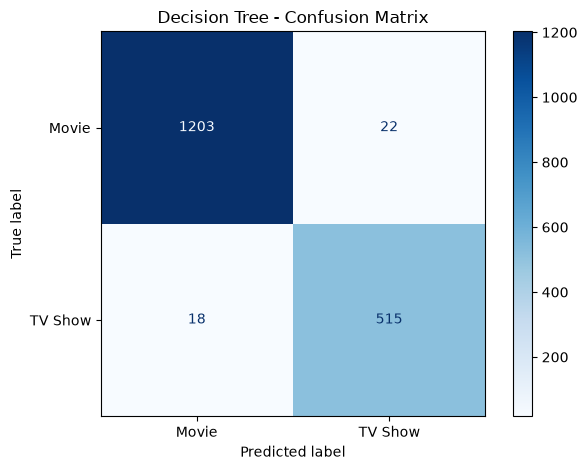

In [16]:
# Evaluate model performance.
print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred_tree), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

# Visualize classification errors.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    labels=decision_tree_model.classes_,
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

### Interpretation of Decision Tree Results

My Decision Tree classifier achieved 97.72% accuracy on the test dataset, with an F1-score of 0.98 for Movies and 0.96 for TV Shows. The model performed well across both classes, although its overall accuracy was 1.48 percentage points lower than that of Logistic Regression.

These results suggest that the Decision Tree can learn useful classification patterns from the selected metadata, but it has not yet outperformed my baseline supervised model. I will evaluate a Random Forest classifier next to determine whether combining multiple decision trees improves predictive performance.

## Step 7: Train the Random Forest Classifier

I will train a Random Forest classifier to evaluate whether an ensemble of decision trees can improve classification performance. Random Forest introduces variation among the trees and combines their predictions, which can help reduce the instability of an individual Decision Tree.

I will retain the same preprocessing pipeline, training data, and test data to make the results comparable with my previous models.

In [17]:
# Combine preprocessing with the Random Forest classifier.
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model using the training dataset.
random_forest_model.fit(X_train, y_train)

# Predict content types for the held-out test dataset.
y_pred_forest = random_forest_model.predict(X_test)


Random Forest Accuracy: 0.975

Classification Report:
              precision    recall  f1-score   support

       Movie       0.98      0.99      0.98      1225
     TV Show       0.97      0.94      0.96       533

    accuracy                           0.97      1758
   macro avg       0.97      0.97      0.97      1758
weighted avg       0.97      0.97      0.97      1758



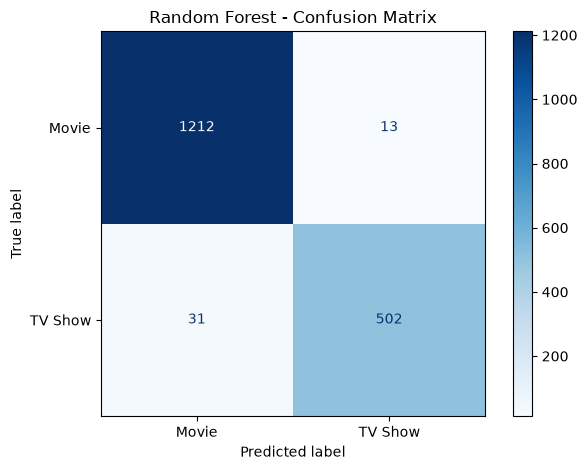

In [18]:
# Evaluate the model.
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_forest), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_forest))

# Display the confusion matrix.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_forest,
    labels=random_forest_model.classes_,
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

### Interpretation of Random Forest Results

My Random Forest classifier achieved 97.50% accuracy on the test dataset. It recorded an F1-score of 0.98 for Movies and 0.96 for TV Shows. Although the model performed well overall, its recall for TV Shows was 0.94, indicating that it missed a greater proportion of actual TV Shows than Logistic Regression baseline model.

The Random Forest did not outperform either Logistic Regression or the Decision Tree in overall accuracy. I will consolidate the evaluation metrics from all three classifiers to identify the strongest-performing model and examine the trade-offs in class-level performance.

### Comparing Classification Models

I will compare Logistic Regression, Decision Tree, and Random Forest using the same test dataset. I will examine accuracy, macro-averaged precision, recall, and F1-score to evaluate overall performance, giving equal weight to Movies and TV Shows across the macro-averaged metrics.

This comparison will help me identify the most suitable model for the current classification task. I will consider both the overall scores and the models' ability to identify each content type before selecting a preferred model.

In [19]:
# Store the predictions from each trained classifier.
model_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest
}

# Calculate the same evaluation metrics for every model.
comparison_results = []

for model_name, predictions in model_predictions.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

# Rank models by test accuracy for an initial comparison.
comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.9920,0.9916,0.9895,0.9906
1,Decision Tree,0.9772,0.9721,0.9741,0.9731
2,Random Forest,0.9750,0.9749,0.9656,0.9701


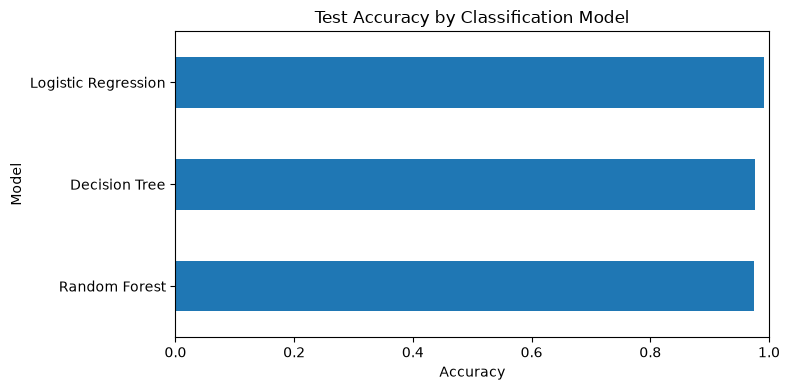

In [20]:

# Compare test accuracy across the three classifiers.
plot_df = comparison_df.sort_values("Accuracy")

ax = plot_df.plot(
    x="Model",
    y="Accuracy",
    kind="barh",
    legend=False,
    figsize=(8, 4)
)

ax.set_title("Test Accuracy by Classification Model")
ax.set_xlabel("Accuracy")
ax.set_ylabel("Model")
ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()


#### Interpretation of Model Comparison

My model comparison shows that Logistic Regression achieved the strongest performance across all four evaluation metrics, with 99.20% accuracy and a macro F1-score of 0.9906. The Decision Tree achieved 97.72% accuracy, while the Random Forest achieved 97.50%.

Logistic Regression performed best overall and maintained balanced performance across the Movie and TV Show classes. Based on these results, I will use it as my leading candidate for further evaluation.

However, these scores should be interpreted in the context of my selected features. In particular, `listed_in` contains genre-category information that may be strongly associated with a title's content type. I will investigate how much the model depends on this feature before drawing conclusions about its reliability on new data.

#### Testing whether listed_in is driving the high accuracy
This is an important validation step. A feature can be legitimate and useful, but if it makes the target almost directly inferable, the model may be less useful for other prediction scenarios.

In [21]:
# Check how well Logistic Regression performs without genre-category labels.
features_without_genres = [
    "release_year",
    "genre_count",
    "country",
    "rating"
]

X_reduced = df[features_without_genres].copy()

# Use the same split settings to make the comparison fair.
X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = train_test_split(
    X_reduced,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Reuse the same preprocessing approach without the listed_in feature.
reduced_preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, ["release_year", "genre_count"]),
    ("categorical", categorical_transformer, ["country", "rating"])
])

reduced_logistic_model = Pipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

reduced_logistic_model.fit(X_train_reduced, y_train_reduced)
y_pred_reduced = reduced_logistic_model.predict(X_test_reduced)

print("Accuracy without listed_in:",
      round(accuracy_score(y_test_reduced, y_pred_reduced), 4))
print("Macro F1 without listed_in:",
      round(f1_score(y_test_reduced, y_pred_reduced, average="macro"), 4))

Accuracy without listed_in: 0.7901
Macro F1 without listed_in: 0.729


### Feature Ablation Analysis: Evaluating the Influence of `listed_in`

To understand how much my model relies on genre-category information, I retrained Logistic Regression after removing the `listed_in` feature while keeping the same train-test split strategy and preprocessing approach.

With all five selected features, my model achieved 99.20% accuracy and a macro F1-score of 0.9906. After removing `listed_in`, accuracy decreased to 79.01%, while macro F1 fell to 0.7290.

This substantial decline indicates that `listed_in` provides important predictive information for distinguishing Movies from TV Shows. The result also shows that the model's high initial performance depends considerably on the information available in this feature.

I will therefore interpret the original model's performance in the context of its input features rather than treating the accuracy score alone as evidence of generalizability. If genre-category information is available when predictions are made, the feature may be useful. If the intended application requires predictions before genre categories are assigned, the reduced-feature model may provide a more relevant starting point, although its class-level performance requires further investigation.

***Checking the class-level performance of the reduced-feature model before deciding which version to present as the preferred model.***

In [22]:
# Examine whether the reduced model performs well for both content types.
print(classification_report(
    y_test_reduced,
    y_pred_reduced,
    zero_division=0
))

# Inspect which types of errors the reduced model makes.
print(confusion_matrix(
    y_test_reduced,
    y_pred_reduced,
    labels=["Movie", "TV Show"]
))

              precision    recall  f1-score   support

       Movie       0.81      0.91      0.86      1225
     TV Show       0.71      0.52      0.60       533

    accuracy                           0.79      1758
   macro avg       0.76      0.71      0.73      1758
weighted avg       0.78      0.79      0.78      1758

[[1112  113]
 [ 256  277]]


### Class-Level Evaluation of the Reduced Logistic Regression Model

After removing `listed_in`, I evaluated the model's performance separately for Movies and TV Shows to understand how the feature reduction affected each class.

The model achieved 79.01% accuracy and a macro F1-score of 0.73. Its recall was 0.91 for Movies but only 0.52 for TV Shows. Out of 533 actual TV Shows in the test set, the model correctly identified 277 and misclassified 256 as Movies.

These results indicate that the reduced model is considerably better at identifying Movies than TV Shows. Although it can still learn useful patterns from release year, genre count, country, and content rating, these features alone do not distinguish the two content types as effectively as the complete feature set.

Combined with my earlier feature ablation results, this analysis suggests that `listed_in` contributes substantially to the model's ability to distinguish Movies from TV Shows. I will consider the intended prediction scenario when selecting my preferred model and interpreting its performance.

### Step 7: Performing Feature Importance Analysis using Permutation importance

After comparing my classification models and testing the influence of `listed_in`, I will examine the contribution of each input feature to my Logistic Regression model's performance.

I will use permutation importance on the held-out test dataset. This method measures how much model performance decreases when the values of one feature are randomly shuffled while the other features remain unchanged.

This analysis will help me identify which metadata fields provide the most useful predictive information. I will interpret the results as measures of predictive importance rather than evidence of causation.

In [23]:
from sklearn.inspection import permutation_importance

# Measure how much each feature contributes to macro F1 on the test set.
importance_result = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Keep the results tied to the original input feature names.
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Importance": importance_result.importances_mean,
    "Std Importance": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "Mean Importance", ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

,Feature,Mean Importance,Std Importance
0,listed_in,0.4325,0.0093
1,rating,0.0631,0.0032
2,country,0.0173,0.0038
3,genre_count,0.0079,0.0023
4,release_year,0.0026,0.0016


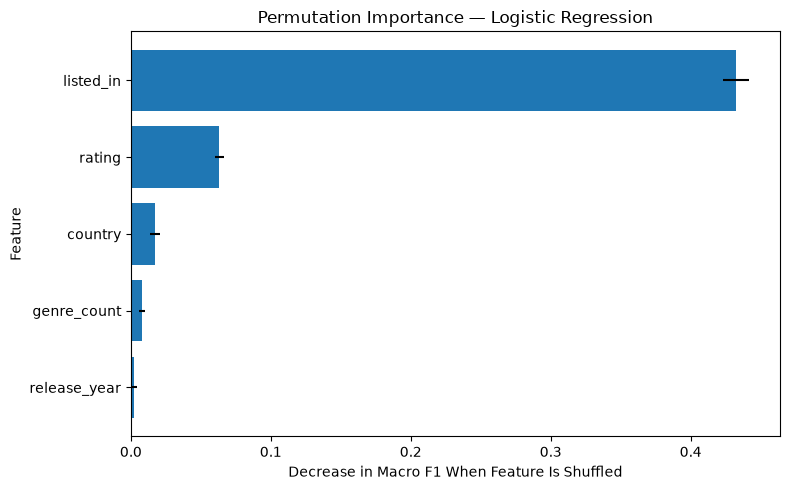

In [24]:
# Plot the features from most to least important.
plot_df = importance_df.sort_values("Mean Importance")

plt.figure(figsize=(8, 5))
plt.barh(
    plot_df["Feature"],
    plot_df["Mean Importance"],
    xerr=plot_df["Std Importance"]
)
plt.xlabel("Decrease in Macro F1 When Feature Is Shuffled")
plt.ylabel("Feature")
plt.title("Permutation Importance — Logistic Regression")
plt.tight_layout()
plt.show()

#### Interpretation of Permutation Importance

My permutation importance analysis identified `listed_in` as the most influential feature in my Logistic Regression model, with a mean macro F1 decrease of 0.4325 when its values were shuffled. This was substantially greater than the contribution of `rating` (0.0631), `country` (0.0173), `genre_count` (0.0079), and `release_year` (0.0026).

The results indicate that genre-category information provides the strongest predictive signal for distinguishing Movies from TV Shows in my dataset. Content rating is the second most influential feature, while country of origin, genre count, and release year contribute comparatively less to the model's predictive performance.

These findings are consistent with my feature ablation experiment, in which removing `listed_in` reduced test accuracy from 99.20% to 79.01% and macro F1 from 0.9906 to 0.7290.

I interpret these results as evidence of predictive association rather than causation. The importance of `listed_in` also highlights the need to consider when this information becomes available in a real-world classification workflow.

## Step 15: Conclusions and Recommendations

### Key Findings

My classification experiments showed that Logistic Regression achieved the strongest overall performance among the three supervised models evaluated. Using all five selected features, it achieved 99.20% test accuracy and a macro F1-score of 0.9906, outperforming both Decision Tree and Random Forest.

My feature ablation experiment showed that removing `listed_in` reduced accuracy to 79.01% and macro F1 to 0.7290. The reduced model also performed unevenly across the two classes, with 0.91 recall for Movies and 0.52 recall for TV Shows.

Permutation importance confirmed that `listed_in` contributed the strongest predictive signal, followed by `rating` and `country`. These findings show that the model's performance depends considerably on the availability of genre-category information.

### Recommendations

1. **Select Logistic Regression as the leading model for the current task.** It achieved the best test-set results among the three models evaluated.
2. **Confirm feature availability before deployment.** The `listed_in` feature is highly influential, so it should only be used where genre-category information is available at prediction time.
3. **Improve TV Show detection when genre categories are unavailable.** The reduced model's 0.52 recall for TV Shows indicates a need for further feature engineering, model evaluation, and potentially threshold tuning.
4. **Validate generalization on additional data.** A separate dataset or later-period test set would help establish whether the observed performance holds beyond the current random split.
5. **Document the model's limitations.** The results describe performance on the available Netflix dataset and do not establish that the model will perform equally well in other content catalogs or production environments.

### Final Conclusion

This project demonstrates how I applied supervised machine learning to classify Netflix titles, compare model performance, investigate feature contributions, and evaluate the impact of removing an influential feature. The results highlight the importance of combining predictive performance metrics with feature-level analysis and an understanding of how the model would be used in practice.